In [ ]:
# Data Exploration and Preprocessing

import torch
import torchvision
from torchvision import transforms
from torch.utils.data import random_split, DataLoader
from datetime import datetime
import time


# Load MNIST dataset with standard normalization
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_train = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_test = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Dataset info
num_samples = len(mnist_train) + len(mnist_test)
sample_shape = mnist_train[0][0].shape
labels = set([lbl for _, lbl in mnist_train])
min_value = mnist_train[0][0].min().item()
max_value = mnist_train[0][0].max().item()
missing_info = False  # MNIST has no missing features

# Split: 80% train, 20% validation, use test set as-is
train_size = int(0.8 * len(mnist_train))
val_size = len(mnist_train) - train_size
train_dataset, val_dataset = random_split(mnist_train, [train_size, val_size])

print("Results:")
print(f"Total samples: {num_samples}")
print(f"Sample shape: {sample_shape}")
print(f"Labels: {labels}")
print(f"Min/Max value: {min_value}/{max_value}")
print(f"Missing info: {missing_info}")
print(f"Train/Val/Test: {train_size}/{val_size}/{len(mnist_test)}")


Results:
Total samples: 70000
Sample shape: torch.Size([1, 28, 28])
Labels: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9}
Min/Max value: -0.4242129623889923/2.821486711502075
Missing info: False
Train/Val/Test: 48000/12000/10000


In [ ]:
# Model Architectures

import torch.nn as nn

# Fully Connected DNN Model
class DNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )
    def forward(self, x):
        return self.layers(x)

#  ConvNet
class SimpleConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64), nn.ReLU(),
            nn.Linear(64, 10)
        )
    def forward(self, x):
        return self.fc(self.conv(x))

# Pre-defined ResNet
from torchvision.models import resnet18

def build_resnet():
    model = resnet18(pretrained=False, num_classes=10)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    return model


In [ ]:
# Loss Function

import torch.optim as optim

def get_loss():
    return nn.CrossEntropyLoss()


In [ ]:
# Optimization

def get_optimizer(model, lr):
    return optim.Adam(model.parameters(), lr=lr)


In [ ]:
# Model Selection / Hyperparameter Tuning

# Test different learning rates
learning_rates = [0.1, 0.01, 0.001]
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(mnist_test, batch_size=batch_size)

from sklearn.metrics import f1_score, roc_auc_score, accuracy_score

def train_and_evaluate(model_class, lr, epochs=5):
    # Build model (keeps your existing logic)
    model = model_class() if model_class != build_resnet else model_class()
    optimizer = get_optimizer(model, lr)
    loss_fn = get_loss()
    train_f1s, val_f1s = [], []

    print(f"[{datetime.now()}] Training run start (model={model_class.__name__}, lr={lr})")
    for epoch in range(epochs):
        # Epoch start timestamp
        epoch_start_wall = datetime.now()
        epoch_start = time.perf_counter()
        print(f"[{epoch_start_wall}] Epoch {epoch+1}/{epochs} start (lr={lr})")

        # Training phase
        model.train()
        all_preds, all_labels = [], []
        for X, y in train_loader:
            optimizer.zero_grad()
            y_hat = model(X)
            loss = loss_fn(y_hat, y)
            loss.backward()
            optimizer.step()
            all_labels.extend(y.numpy())
            all_preds.extend(torch.argmax(y_hat, 1).numpy())
        f1_train = f1_score(all_labels, all_preds, average='macro')
        train_f1s.append(f1_train)

        # Validation phase
        model.eval()
        val_preds, val_labels = [], []
        with torch.no_grad():
            for X, y in val_loader:
                y_hat = model(X)
                val_labels.extend(y.numpy())
                val_preds.extend(torch.argmax(y_hat, 1).numpy())
        f1_val = f1_score(val_labels, val_preds, average='macro')
        val_f1s.append(f1_val)

        # Epoch end timestamp and elapsed
        epoch_end_wall = datetime.now()
        elapsed = time.perf_counter() - epoch_start
        print(f"[{epoch_end_wall}] Epoch {epoch+1} end | Train F1={f1_train:.4f} | Val F1={f1_val:.4f} | Elapsed={elapsed:.2f}s")

    print(f"[{datetime.now()}] Training run end   (model={model_class.__name__}, lr={lr})")
    return model, train_f1s, val_f1s



In [ ]:
# F1 & AUC Reporting

def report_test_performance(model, test_loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for X, y in test_loader:
            out = model(X)
            preds.extend(torch.argmax(out, 1).numpy())
            labels.extend(y.numpy())
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average='macro')
    print(f"Test Accuracy: {acc:.4f}")
    print(f"Test F1 Score: {f1:.4f}")
    return acc, f1

# Training Plots
import matplotlib.pyplot as plt

def plot_training_stats(train_stats, val_stats, title="F1 Score"):
    plt.plot(train_stats, label="Train F1")
    plt.plot(val_stats, label="Validation F1")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("F1 Score")
    plt.legend()
    plt.show()


In [ ]:
# Model Testing Function

def testmodel(model, test_loader):
    # Predict on test set, return predicted labels
    model.eval()
    predicts = []
    with torch.no_grad():
        for X, _ in test_loader:
            out = model(X)
            predicts.extend(torch.argmax(out, 1).numpy())
    return predicts


Training DNN model with learning rate 0.1:
[2025-10-27 01:03:03.775829] Training run start (model=DNN, lr=0.1)
[2025-10-27 01:03:03.775889] Epoch 1/5 start (lr=0.1)
[2025-10-27 01:03:19.232593] Epoch 1 end | Train F1=0.3031 | Val F1=0.2499 | Elapsed=15.46s
[2025-10-27 01:03:19.232732] Epoch 2/5 start (lr=0.1)
[2025-10-27 01:03:35.502765] Epoch 2 end | Train F1=0.2202 | Val F1=0.0734 | Elapsed=16.27s
[2025-10-27 01:03:35.502899] Epoch 3/5 start (lr=0.1)
[2025-10-27 01:03:52.377731] Epoch 3 end | Train F1=0.1518 | Val F1=0.0712 | Elapsed=16.87s
[2025-10-27 01:03:52.377853] Epoch 4/5 start (lr=0.1)
[2025-10-27 01:04:09.378114] Epoch 4 end | Train F1=0.1390 | Val F1=0.0435 | Elapsed=17.00s
[2025-10-27 01:04:09.378216] Epoch 5/5 start (lr=0.1)
[2025-10-27 01:04:24.915521] Epoch 5 end | Train F1=0.1070 | Val F1=0.0233 | Elapsed=15.54s
[2025-10-27 01:04:24.915617] Training run end   (model=DNN, lr=0.1)
Test Accuracy: 0.1150
Test F1 Score: 0.0233


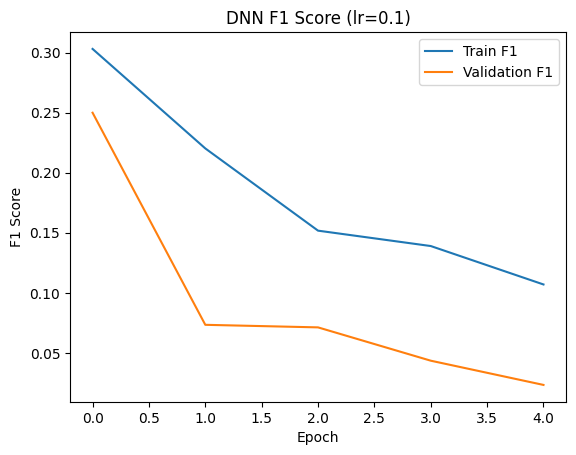

Training DNN model with learning rate 0.01:
[2025-10-27 01:04:27.307873] Training run start (model=DNN, lr=0.01)
[2025-10-27 01:04:27.307948] Epoch 1/5 start (lr=0.01)
[2025-10-27 01:04:41.488403] Epoch 1 end | Train F1=0.9116 | Val F1=0.9381 | Elapsed=14.18s
[2025-10-27 01:04:41.488500] Epoch 2/5 start (lr=0.01)
[2025-10-27 01:04:57.382286] Epoch 2 end | Train F1=0.9453 | Val F1=0.9433 | Elapsed=15.89s
[2025-10-27 01:04:57.382399] Epoch 3/5 start (lr=0.01)
[2025-10-27 01:05:12.398316] Epoch 3 end | Train F1=0.9514 | Val F1=0.9388 | Elapsed=15.02s
[2025-10-27 01:05:12.398414] Epoch 4/5 start (lr=0.01)
[2025-10-27 01:05:27.309620] Epoch 4 end | Train F1=0.9566 | Val F1=0.9490 | Elapsed=14.91s
[2025-10-27 01:05:27.309740] Epoch 5/5 start (lr=0.01)
[2025-10-27 01:05:43.517682] Epoch 5 end | Train F1=0.9594 | Val F1=0.9511 | Elapsed=16.21s
[2025-10-27 01:05:43.517811] Training run end   (model=DNN, lr=0.01)
Test Accuracy: 0.9524
Test F1 Score: 0.9521


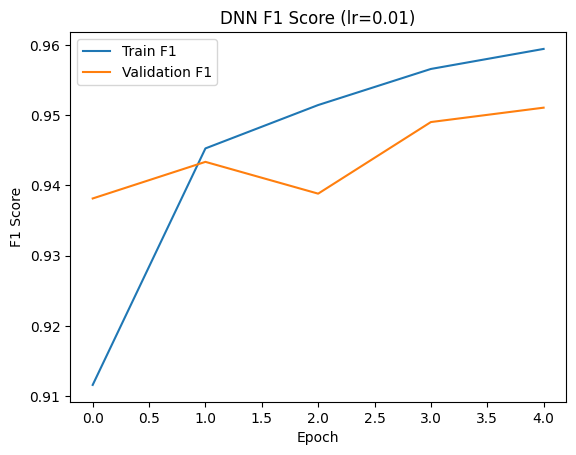

Training DNN model with learning rate 0.001:
[2025-10-27 01:05:46.427079] Training run start (model=DNN, lr=0.001)
[2025-10-27 01:05:46.427113] Epoch 1/5 start (lr=0.001)
[2025-10-27 01:06:01.184005] Epoch 1 end | Train F1=0.9090 | Val F1=0.9487 | Elapsed=14.76s
[2025-10-27 01:06:01.184101] Epoch 2/5 start (lr=0.001)
[2025-10-27 01:06:15.628508] Epoch 2 end | Train F1=0.9602 | Val F1=0.9615 | Elapsed=14.44s
[2025-10-27 01:06:15.628605] Epoch 3/5 start (lr=0.001)
[2025-10-27 01:06:29.632986] Epoch 3 end | Train F1=0.9728 | Val F1=0.9638 | Elapsed=14.00s
[2025-10-27 01:06:29.633086] Epoch 4/5 start (lr=0.001)
[2025-10-27 01:06:43.841324] Epoch 4 end | Train F1=0.9802 | Val F1=0.9656 | Elapsed=14.21s
[2025-10-27 01:06:43.841431] Epoch 5/5 start (lr=0.001)
[2025-10-27 01:06:58.405309] Epoch 5 end | Train F1=0.9850 | Val F1=0.9642 | Elapsed=14.56s
[2025-10-27 01:06:58.405430] Training run end   (model=DNN, lr=0.001)
Test Accuracy: 0.9654
Test F1 Score: 0.9652


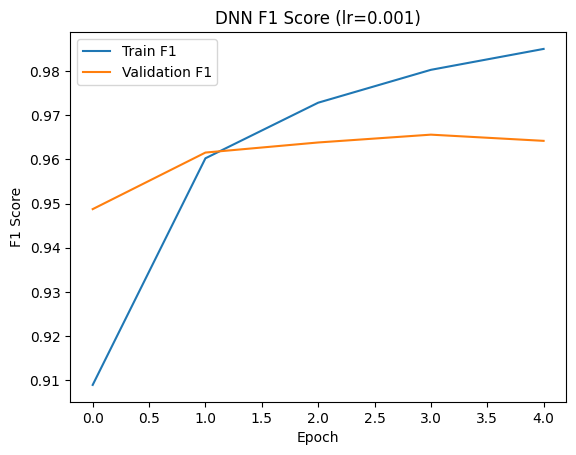

Training ConvNet model with learning rate 0.1:
[2025-10-27 01:07:01.130160] Training run start (model=SimpleConvNet, lr=0.1)
[2025-10-27 01:07:01.130190] Epoch 1/5 start (lr=0.1)
[2025-10-27 01:07:27.831635] Epoch 1 end | Train F1=0.0846 | Val F1=0.0194 | Elapsed=26.70s
[2025-10-27 01:07:27.831733] Epoch 2/5 start (lr=0.1)
[2025-10-27 01:07:55.044520] Epoch 2 end | Train F1=0.0853 | Val F1=0.0194 | Elapsed=27.21s
[2025-10-27 01:07:55.044622] Epoch 3/5 start (lr=0.1)
[2025-10-27 01:08:22.752862] Epoch 3 end | Train F1=0.0853 | Val F1=0.0194 | Elapsed=27.71s
[2025-10-27 01:08:22.752963] Epoch 4/5 start (lr=0.1)
[2025-10-27 01:08:51.035505] Epoch 4 end | Train F1=0.0850 | Val F1=0.0194 | Elapsed=28.28s
[2025-10-27 01:08:51.035621] Epoch 5/5 start (lr=0.1)
[2025-10-27 01:09:18.746699] Epoch 5 end | Train F1=0.0852 | Val F1=0.0194 | Elapsed=27.71s
[2025-10-27 01:09:18.746852] Training run end   (model=SimpleConvNet, lr=0.1)
Test Accuracy: 0.1135
Test F1 Score: 0.0204


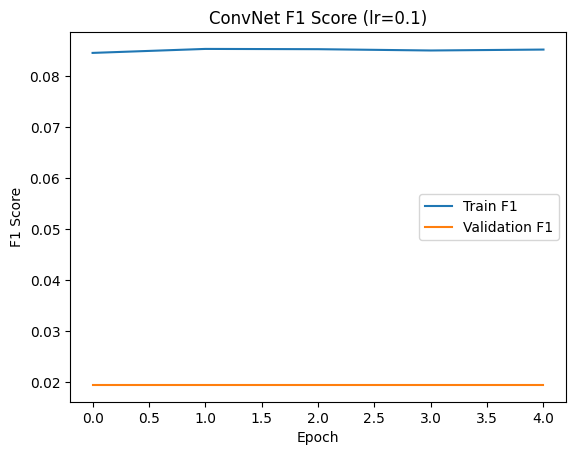

Training ConvNet model with learning rate 0.01:
[2025-10-27 01:09:22.227980] Training run start (model=SimpleConvNet, lr=0.01)
[2025-10-27 01:09:22.228026] Epoch 1/5 start (lr=0.01)
[2025-10-27 01:09:50.508131] Epoch 1 end | Train F1=0.9496 | Val F1=0.9749 | Elapsed=28.28s
[2025-10-27 01:09:50.508246] Epoch 2/5 start (lr=0.01)
[2025-10-27 01:10:18.204985] Epoch 2 end | Train F1=0.9769 | Val F1=0.9738 | Elapsed=27.70s
[2025-10-27 01:10:18.205081] Epoch 3/5 start (lr=0.01)
[2025-10-27 01:10:45.056452] Epoch 3 end | Train F1=0.9813 | Val F1=0.9739 | Elapsed=26.85s
[2025-10-27 01:10:45.056569] Epoch 4/5 start (lr=0.01)
[2025-10-27 01:11:13.542477] Epoch 4 end | Train F1=0.9817 | Val F1=0.9757 | Elapsed=28.49s
[2025-10-27 01:11:13.542637] Epoch 5/5 start (lr=0.01)
[2025-10-27 01:11:43.636237] Epoch 5 end | Train F1=0.9822 | Val F1=0.9743 | Elapsed=30.09s
[2025-10-27 01:11:43.636360] Training run end   (model=SimpleConvNet, lr=0.01)
Test Accuracy: 0.9776
Test F1 Score: 0.9774


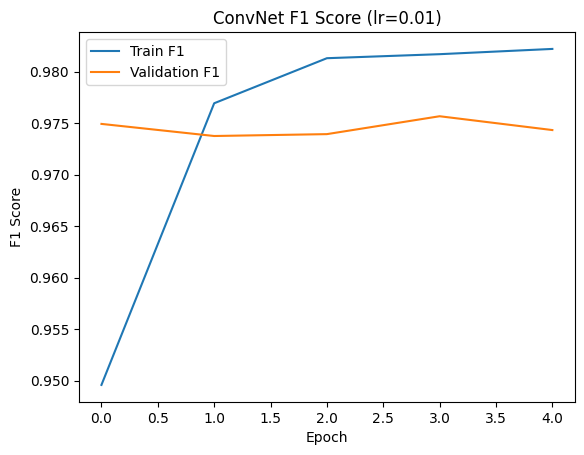

Training ConvNet model with learning rate 0.001:
[2025-10-27 01:11:47.807264] Training run start (model=SimpleConvNet, lr=0.001)
[2025-10-27 01:11:47.807305] Epoch 1/5 start (lr=0.001)
[2025-10-27 01:12:16.623174] Epoch 1 end | Train F1=0.9261 | Val F1=0.9726 | Elapsed=28.82s
[2025-10-27 01:12:16.623266] Epoch 2/5 start (lr=0.001)
[2025-10-27 01:12:47.732893] Epoch 2 end | Train F1=0.9785 | Val F1=0.9797 | Elapsed=31.11s
[2025-10-27 01:12:47.733007] Epoch 3/5 start (lr=0.001)
[2025-10-27 01:13:19.367245] Epoch 3 end | Train F1=0.9852 | Val F1=0.9807 | Elapsed=31.63s
[2025-10-27 01:13:19.367342] Epoch 4/5 start (lr=0.001)
[2025-10-27 01:13:48.477543] Epoch 4 end | Train F1=0.9886 | Val F1=0.9816 | Elapsed=29.11s
[2025-10-27 01:13:48.477648] Epoch 5/5 start (lr=0.001)
[2025-10-27 01:14:16.460258] Epoch 5 end | Train F1=0.9918 | Val F1=0.9819 | Elapsed=27.98s
[2025-10-27 01:14:16.460353] Training run end   (model=SimpleConvNet, lr=0.001)
Test Accuracy: 0.9840
Test F1 Score: 0.9839


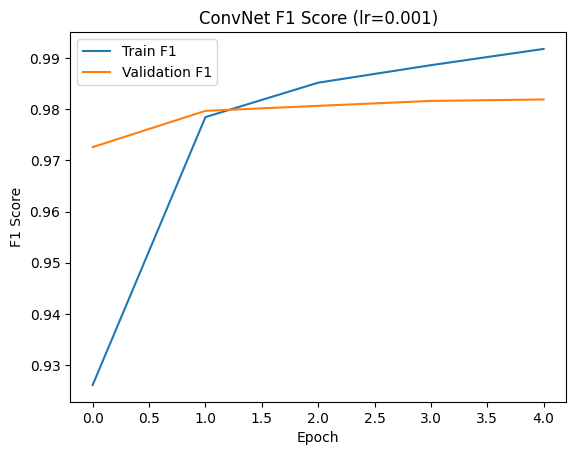

Training ResNet model with learning rate 0.1:
[2025-10-27 01:14:20.287104] Training run start (model=build_resnet, lr=0.1)
[2025-10-27 01:14:20.287204] Epoch 1/5 start (lr=0.1)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


[2025-10-27 01:19:53.795964] Epoch 1 end | Train F1=0.7152 | Val F1=0.9585 | Elapsed=333.51s
[2025-10-27 01:19:53.796082] Epoch 2/5 start (lr=0.1)
[2025-10-27 01:26:49.296748] Epoch 2 end | Train F1=0.9603 | Val F1=0.9617 | Elapsed=415.50s
[2025-10-27 01:26:49.296908] Epoch 3/5 start (lr=0.1)
[2025-10-27 01:33:41.595333] Epoch 3 end | Train F1=0.9712 | Val F1=0.9761 | Elapsed=412.30s
[2025-10-27 01:33:41.595462] Epoch 4/5 start (lr=0.1)
[2025-10-27 01:40:36.101767] Epoch 4 end | Train F1=0.9723 | Val F1=0.8130 | Elapsed=414.51s
[2025-10-27 01:40:36.101928] Epoch 5/5 start (lr=0.1)
[2025-10-27 01:47:30.030709] Epoch 5 end | Train F1=0.9584 | Val F1=0.9800 | Elapsed=413.93s
[2025-10-27 01:47:30.030839] Training run end   (model=build_resnet, lr=0.1)
Test Accuracy: 0.9827
Test F1 Score: 0.9825


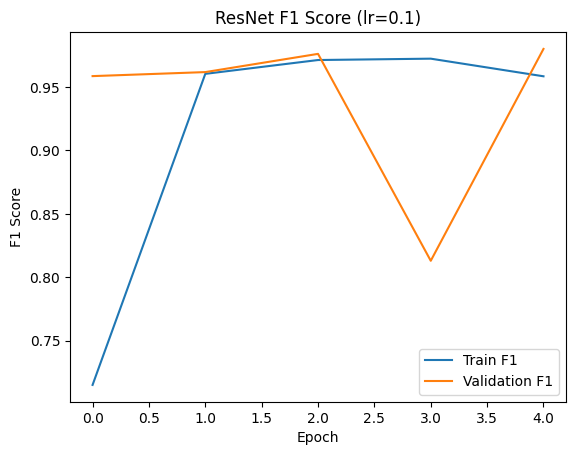

Training ResNet model with learning rate 0.01:
[2025-10-27 01:47:43.177353] Training run start (model=build_resnet, lr=0.01)
[2025-10-27 01:47:43.177473] Epoch 1/5 start (lr=0.01)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


[2025-10-27 01:52:59.003859] Epoch 1 end | Train F1=0.9427 | Val F1=0.9633 | Elapsed=315.83s
[2025-10-27 01:52:59.003996] Epoch 2/5 start (lr=0.01)
[2025-10-27 01:58:31.910900] Epoch 2 end | Train F1=0.9778 | Val F1=0.9767 | Elapsed=332.91s
[2025-10-27 01:58:31.911032] Epoch 3/5 start (lr=0.01)
[2025-10-27 02:03:59.086901] Epoch 3 end | Train F1=0.9818 | Val F1=0.9807 | Elapsed=327.18s
[2025-10-27 02:03:59.087018] Epoch 4/5 start (lr=0.01)
[2025-10-27 02:09:23.480575] Epoch 4 end | Train F1=0.9851 | Val F1=0.9828 | Elapsed=324.39s
[2025-10-27 02:09:23.480988] Epoch 5/5 start (lr=0.01)
[2025-10-27 02:14:44.668546] Epoch 5 end | Train F1=0.9871 | Val F1=0.9777 | Elapsed=321.19s
[2025-10-27 02:14:44.668678] Training run end   (model=build_resnet, lr=0.01)
Test Accuracy: 0.9823
Test F1 Score: 0.9823


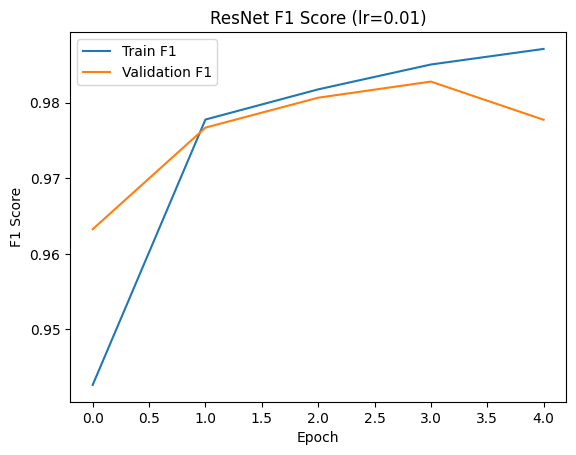

Training ResNet model with learning rate 0.001:
[2025-10-27 02:14:57.773229] Training run start (model=build_resnet, lr=0.001)
[2025-10-27 02:14:57.773339] Epoch 1/5 start (lr=0.001)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


[2025-10-27 02:20:08.959977] Epoch 1 end | Train F1=0.9554 | Val F1=0.9768 | Elapsed=311.19s
[2025-10-27 02:20:08.960112] Epoch 2/5 start (lr=0.001)
[2025-10-27 02:25:27.478204] Epoch 2 end | Train F1=0.9807 | Val F1=0.9828 | Elapsed=318.52s
[2025-10-27 02:25:27.478317] Epoch 3/5 start (lr=0.001)
[2025-10-27 02:30:45.007429] Epoch 3 end | Train F1=0.9867 | Val F1=0.9741 | Elapsed=317.53s
[2025-10-27 02:30:45.007541] Epoch 4/5 start (lr=0.001)
[2025-10-27 02:36:04.621400] Epoch 4 end | Train F1=0.9887 | Val F1=0.9866 | Elapsed=319.61s
[2025-10-27 02:36:04.621508] Epoch 5/5 start (lr=0.001)
[2025-10-27 02:41:22.389220] Epoch 5 end | Train F1=0.9910 | Val F1=0.9852 | Elapsed=317.77s
[2025-10-27 02:41:22.389339] Training run end   (model=build_resnet, lr=0.001)
Test Accuracy: 0.9877
Test F1 Score: 0.9876


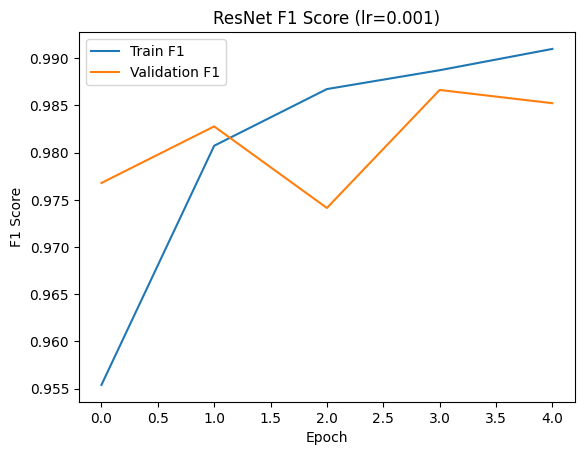

In [ ]:
# Running and Comparing All Models

models = {"DNN": DNN, "ConvNet": SimpleConvNet, "ResNet": build_resnet}
results = {}

for name, model_class in models.items():
    for lr in learning_rates:
        print(f"Training {name} model with learning rate {lr}:")
        model, train_f1s, val_f1s = train_and_evaluate(model_class, lr, epochs=5)
        acc, f1 = report_test_performance(model, test_loader)
        results[(name, lr)] = {"accuracy": acc, "f1": f1}
        plot_training_stats(train_f1s, val_f1s, title=f"{name} F1 Score (lr={lr})")
        # Save best model weights, predicted labels
        torch.save(model.state_dict(), f"{name}_lr{lr}_best.pth")


In [ ]:
#  Results Table

import pandas as pd

df_results = pd.DataFrame([
    {"Model": name, "Learning Rate": lr, "Test Accuracy": results[(name, lr)]["accuracy"], "Test F1": results[(name, lr)]["f1"]}
    for (name, lr) in results
])
print(df_results)


     Model  Learning Rate  Test Accuracy   Test F1
0      DNN          0.100         0.1150  0.023271
1      DNN          0.010         0.9524  0.952072
2      DNN          0.001         0.9654  0.965163
3  ConvNet          0.100         0.1135  0.020386
4  ConvNet          0.010         0.9776  0.977373
5  ConvNet          0.001         0.9840  0.983867
6   ResNet          0.100         0.9827  0.982549
7   ResNet          0.010         0.9823  0.982286
8   ResNet          0.001         0.9877  0.987551
